# Lab M1 — One qubit: rotations, measurement, shot noise
Quantum Computing Research Internship 2026 · Module 1


# 0. Package install

Requirement:
* Pennylane


In [ ]:
%%capture

!pip -q install pennylane

import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml

print("PennyLane", qml.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 776.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 51.5 MB/s eta 0:00:00
PennyLane 0.45.1


# 1. Measurement — The Born rule


$$|\psi\rangle = R_y(\theta)|0\rangle = \cos\tfrac{\theta}{2}|0\rangle + \sin\tfrac{\theta}{2}|1\rangle,\qquad P(0)=|\alpha|^2=\mathrm{cos}\:^{2}\tfrac{\theta}{2},\quad P(1)=|\beta|^2=\sin\:^2\tfrac{\theta}{2}$$

## A. The circuit

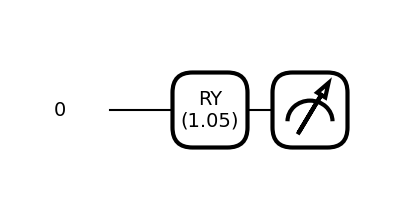

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml

# Quantum device - default.qubit = noiseless statevector simulation
dev = qml.device("default.qubit", wires=1)


# SYNTAX - Using qnode to turn the pennylane code into quantum circuit
@qml.qnode(dev)
def circuit(theta):
    qml.RY(theta, wires=0)
    return qml.probs(wires=0)


# Draw the circuit
fig, ax = qml.draw_mpl(circuit, decimals=2)(np.pi / 3)
plt.show()

## B. Measurement results

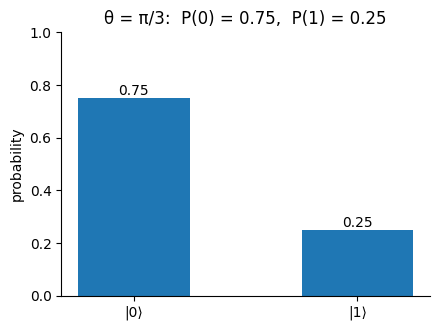

In [44]:
import matplotlib.pyplot as plt
import numpy as np

BLUE, ORANGE = 'tab:blue', 'tab:orange'
theta0 = np.pi / 3

fig1, ax1 = plt.subplots(figsize=(4.5, 3.4))

# Pass theta to the quantum circuit
p = circuit(theta0)

# Plot
bars = ax1.bar(["|0⟩", "|1⟩"], p, color=BLUE, width=0.5)
ax1.bar_label(bars, fmt="%.2f")
ax1.set_ylim(0, 1)
ax1.set_ylabel("probability")
ax1.set_title("θ = π/3:  P(0) = 0.75,  P(1) = 0.25")
ax1.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## C. Sweeping the θ ∈ [0, π]


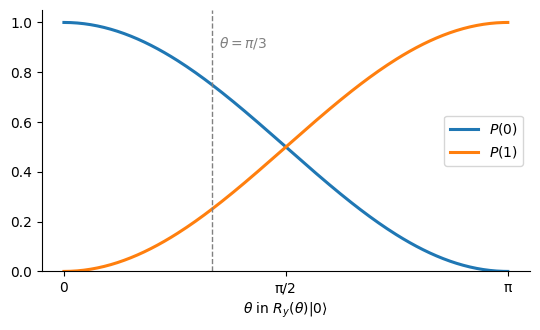

In [45]:
fig2, ax2 = plt.subplots(figsize=(5.5, 3.4))

# Sweeping the thetas
thetas = np.linspace(0, np.pi, 200)
probs = np.array([circuit(t) for t in thetas])  # column 0 = P(0), column 1 = P(1)

# The probs of 0 results
ax2.plot(
    thetas,
    probs[:, 0],
    color=BLUE,
    lw=2.2,
    label=r"$P(0)$",
)

# The probs of 1 results
ax2.plot(
    thetas,
    probs[:, 1],
    color=ORANGE,
    lw=2.2,
    label=r"$P(1)$",
)
ax2.axvline(theta0, color="gray", ls="--", lw=1)
ax2.text(theta0 + 0.05, 0.9, r"$\theta=\pi/3$", color="gray")

ax2.set_xticks([0, np.pi / 2, np.pi])
ax2.set_xticklabels(["0", "π/2", "π"])
ax2.set_xlabel(r"$\theta$ in $R_y(\theta)|0\rangle$")
ax2.set_ylim(0, 1.05)
ax2.legend(loc="center right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

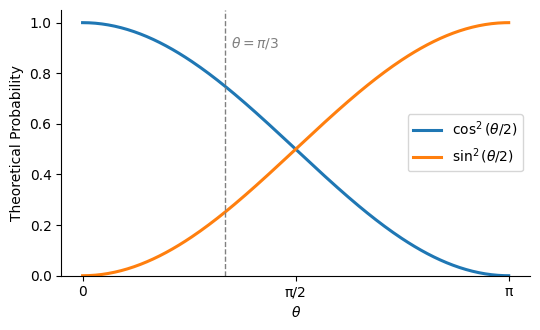

In [ ]:
fig3, ax3 = plt.subplots(figsize=(5.5, 3.4))

# Theoretical
theory_p0 = np.cos(thetas / 2) ** 2
theory_p1 = np.sin(thetas / 2) ** 2

# theory_p0
ax3.plot(
    thetas,
    theory_p0,
    color=BLUE,
    lw=2.2,
    linestyle="-",
    label=r"$\cos^2(\theta/2)$",
)

# theory_p1
ax3.plot(
    thetas,
    theory_p1,
    color=ORANGE,
    lw=2.2,
    linestyle="-",
    label=r"$\sin^2(\theta/2)$",
)

ax3.axvline(theta0, color="gray", ls="--", lw=1)
ax3.text(theta0 + 0.05, 0.9, r"$\theta=\pi/3$", color="gray")

ax3.set_xticks([0, np.pi / 2, np.pi])
ax3.set_xticklabels(["0", "π/2", "π"])
ax3.set_xlabel(r"$\theta$")
ax3.set_ylabel("Theoretical Probability")
ax3.set_ylim(0, 1.05)
ax3.legend(loc="center right")
ax3.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## D. Global phase and relative phase

Same starting state $|0\rangle$, same angle θ — three different rotation gates:

$$R_y(\theta)|0\rangle=\cos\tfrac{\theta}{2}|0\rangle+\sin\tfrac{\theta}{2} |1\rangle
\quad| \quad
R_z(\theta)|0\rangle=e^{-\mathrm{i}\theta/2}\quad|0\rangle
\quad| \quad
R_x(\theta)|0\rangle=\cos\tfrac{\theta}{2}\quad|0\rangle-\mathrm{i}\,\sin\tfrac{\theta}{2}|1\rangle$$


In [46]:
# Get the amplitude alpha and beta
@qml.qnode(dev)
def state_after(gate, theta):
    gate(theta, wires=0)
    return qml.state()                    # the amplitudes (alpha, beta)


# Get the measurement probabilities (0 or 1)
@qml.qnode(dev)
def probs_after(gate, theta):
    gate(theta, wires=0)
    return qml.probs(wires=0)             # P(0), P(1) — what a Z measurement sees



# Return the location of the state on the Bloch sphere
@qml.qnode(dev)
def bloch_vector(gate, theta):
    gate(theta, wires=0)
    return [qml.expval(qml.PauliX(0)), qml.expval(qml.PauliY(0)), qml.expval(qml.PauliZ(0))]


def report(gate, theta):
    psi = state_after(gate, theta)
    print(f"{gate.__name__}({theta:.2f})|0>   state = {np.round(psi, 3)}   "
          f"P = {np.round(probs_after(gate, theta), 3)}   Bloch (X,Y,Z) = {np.round(bloch_vector(gate, theta), 3)}")


report(qml.RY, theta0)

RY(1.05)|0>   state = [0.866+0.j 0.5  +0.j]   P = [0.75 0.25]   Bloch (X,Y,Z) = [0.866 0.    0.5  ]


### D.1 Replace RY with RZ — a global phase changes nothing

$R_z(\theta)|0\rangle = e^{-\mathrm{i}\theta/2}\quad |0\rangle$: the whole state is multiplied by one phase factor. The amplitudes change, but $|\alpha|^2$ does not, and neither does any expectation value.

In [61]:
for t in [0, np.pi / 3, np.pi, 2 * np.pi]:
    report(qml.RZ, t)

RZ(0.00)|0>   state = [1.+0.j 0.+0.j]   P = [1. 0.]   Bloch (X,Y,Z) = [0. 0. 1.]
RZ(1.05)|0>   state = [0.866-0.5j 0.   +0.j ]   P = [1. 0.]   Bloch (X,Y,Z) = [0. 0. 1.]
RZ(3.14)|0>   state = [0.-1.j 0.+0.j]   P = [1. 0.]   Bloch (X,Y,Z) = [0. 0. 1.]
RZ(6.28)|0>   state = [-1.-0.j  0.+0.j]   P = [1. 0.]   Bloch (X,Y,Z) = [0. 0. 1.]


**Global phase**: two states that differ only by a factor $e^{\mathrm{i}\gamma}$ are the **same physical state**. Nothing you can measure tells them apart — drop it. (Example: $R_x(2\pi) = -I$ is the identity for every experiment.)

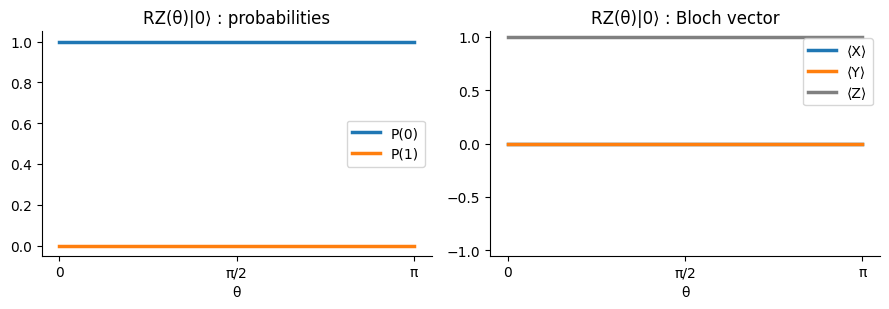

min |<0|RZ(θ)|0>|^2 over the sweep = 1.0


In [59]:
# Sweep theta: every measurable quantity is flat
bv_rz = np.array([bloch_vector(qml.RZ, t) for t in thetas])
p_rz = np.array([probs_after(qml.RZ, t) for t in thetas])

fig4, ax4 = plt.subplots(1, 2, figsize=(9, 3.2))
ax4[0].plot(thetas, p_rz[:, 0], color=BLUE, lw=2.5, label="P(0)")
ax4[0].plot(thetas, p_rz[:, 1], color=ORANGE, lw=2.5, label="P(1)")
ax4[0].set_title("RZ(θ)|0⟩ : probabilities"); ax4[0].set_ylim(-0.05, 1.05); ax4[0].legend()
for k, lab, c in [(0, "⟨X⟩", BLUE), (1, "⟨Y⟩", ORANGE), (2, "⟨Z⟩", "gray")]:
    ax4[1].plot(thetas, bv_rz[:, k], lw=2.5, color=c, label=lab)
ax4[1].set_title("RZ(θ)|0⟩ : Bloch vector"); ax4[1].set_ylim(-1.05, 1.05); ax4[1].legend()
for a in ax4:
    a.set_xticks([0, np.pi / 2, np.pi]); a.set_xticklabels(["0", "π/2", "π"]); a.set_xlabel("θ")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# |<0|psi>|^2 = 1 for all theta -> physically the same state as |0>
overlaps = [abs(state_after(qml.RZ, t)[0]) ** 2 for t in thetas]
print("min |<0|RZ(θ)|0>|^2 over the sweep =", round(min(overlaps), 6))

### D.2 Replace RY with RX — same probabilities, different state: a relative phase

$R_x(\theta)|0\rangle=\cos\tfrac{\theta}{2}|0\rangle-\mathrm{i}\sin\tfrac{\theta}{2}|1\rangle$. Compared with RY the amplitude of $|1\rangle$ carries an extra $-\mathrm{i}$: a phase **between** $|0\rangle$ and $|1\rangle$.

In [49]:
report(qml.RY, theta0)
report(qml.RX, theta0)
# same P = [0.75, 0.25]; different state (-0.5j) and different Bloch vector:
#   RY -> (0.866, 0, 0.5)  arrow in the x-z plane      RX -> (0, -0.866, 0.5)  arrow in the y-z plane

RY(1.05)|0>   state = [0.866+0.j 0.5  +0.j]   P = [0.75 0.25]   Bloch (X,Y,Z) = [0.866 0.    0.5  ]
RX(1.05)|0>   state = [0.866+0.j  0.   -0.5j]   P = [0.75 0.25]   Bloch (X,Y,Z) = [ 0.    -0.866  0.5  ]


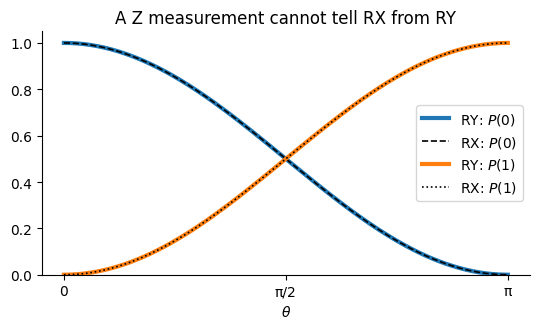

max |P_RY - P_RX| = 0.0


In [62]:
probs_rx = np.array([probs_after(qml.RX, t) for t in thetas])

fig5, ax5 = plt.subplots(figsize=(5.5, 3.4))
ax5.plot(thetas, probs[:, 0], color=BLUE, lw=3, label=r"RY: $P(0)$")
ax5.plot(thetas, probs_rx[:, 0], color="k", lw=1.2, ls="--", label=r"RX: $P(0)$")
ax5.plot(thetas, probs[:, 1], color=ORANGE, lw=3, label=r"RY: $P(1)$")
ax5.plot(thetas, probs_rx[:, 1], color="k", lw=1.2, ls=":", label=r"RX: $P(1)$")
ax5.set_xticks([0, np.pi / 2, np.pi]); ax5.set_xticklabels(["0", "π/2", "π"])
ax5.set_xlabel(r"$\theta$"); ax5.set_ylim(0, 1.05); ax5.legend(loc="center right")
ax5.set_title("A Z measurement cannot tell RX from RY")
ax5.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print("max |P_RY - P_RX| =", np.abs(probs - probs_rx).max())

**Change the point of view**: measure along X and Y as well (= measuring in another basis, slide 27). The arrows have the same height ⟨Z⟩ but point in different directions.

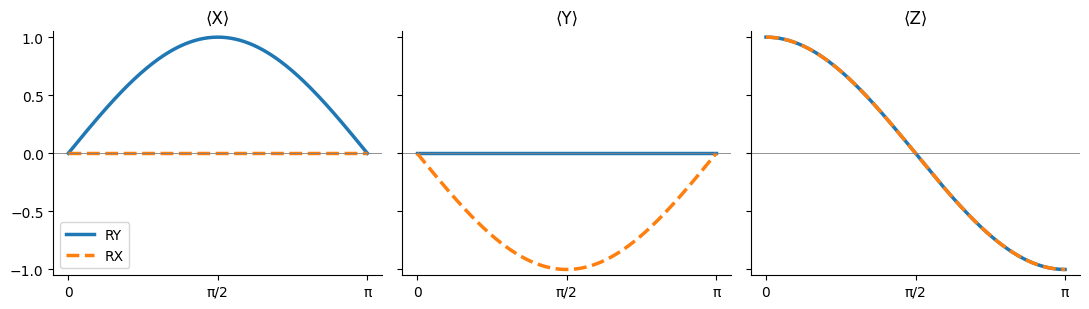

In [51]:
bv_ry = np.array([bloch_vector(qml.RY, t) for t in thetas])
bv_rx = np.array([bloch_vector(qml.RX, t) for t in thetas])

fig6, ax6 = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for k, lab in enumerate(["⟨X⟩", "⟨Y⟩", "⟨Z⟩"]):
    ax6[k].plot(thetas, bv_ry[:, k], color=BLUE, lw=2.5, label="RY")
    ax6[k].plot(thetas, bv_rx[:, k], color=ORANGE, lw=2.5, ls="--", label="RX")
    ax6[k].set_title(lab); ax6[k].set_xticks([0, np.pi / 2, np.pi]); ax6[k].set_xticklabels(["0", "π/2", "π"])
    ax6[k].axhline(0, color="gray", lw=0.6); ax6[k].spines[["top", "right"]].set_visible(False)
ax6[0].legend(); ax6[0].set_ylim(-1.05, 1.05)
plt.tight_layout(); plt.show()
# <Z> identical (same probabilities)  ·  RY lives on <X>, RX lives on <Y>: the -i rotated the arrow from +x to -y

### D.3 Relative phase made visible by interference: H · RZ(θ) · H


RZ on $|0\rangle$ was a global phase (D.1). RZ on $|+\rangle$ is a **relative** phase: $R_z(\theta)|+\rangle \propto \tfrac{1}{\sqrt2}\left(|0\rangle+e^{\mathrm{i}\theta}|1\rangle\right)$.
Measured in Z it is always 50/50; apply H first and the phase turns into a probability.

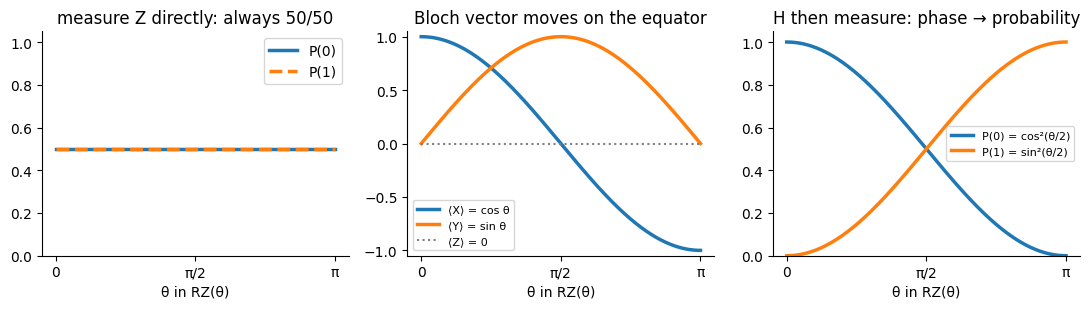

theta = pi :  |+> -> |->    direct [0.5 0.5]    after H [0. 1.]


In [63]:
@qml.qnode(dev)
def rz_on_plus(theta, apply_h=False):
    qml.Hadamard(wires=0)            # |0> -> |+>
    qml.RZ(theta, wires=0)           # relative phase e^{i theta} on |1>
    if apply_h:
        qml.Hadamard(wires=0)        # interference: phase -> probability
    return qml.probs(wires=0)


@qml.qnode(dev)
def rz_on_plus_bloch(theta):
    qml.Hadamard(wires=0)
    qml.RZ(theta, wires=0)
    return [qml.expval(qml.PauliX(0)), qml.expval(qml.PauliY(0)), qml.expval(qml.PauliZ(0))]


p_direct = np.array([rz_on_plus(t) for t in thetas])
p_after_h = np.array([rz_on_plus(t, apply_h=True) for t in thetas])
bv_plus = np.array([rz_on_plus_bloch(t) for t in thetas])

fig7, ax7 = plt.subplots(1, 3, figsize=(11, 3.2))
ax7[0].plot(thetas, p_direct[:, 0], color=BLUE, lw=2.5, label="P(0)")
ax7[0].plot(thetas, p_direct[:, 1], color=ORANGE, lw=2.5, ls="--", label="P(1)")
ax7[0].set_title("measure Z directly: always 50/50"); ax7[0].set_ylim(0, 1.05); ax7[0].legend()

ax7[1].plot(thetas, bv_plus[:, 0], color=BLUE, lw=2.5, label="⟨X⟩ = cos θ")
ax7[1].plot(thetas, bv_plus[:, 1], color=ORANGE, lw=2.5, label="⟨Y⟩ = sin θ")
ax7[1].plot(thetas, bv_plus[:, 2], color="gray", lw=1.5, ls=":", label="⟨Z⟩ = 0")
ax7[1].set_title("Bloch vector moves on the equator"); ax7[1].set_ylim(-1.05, 1.05); ax7[1].legend(fontsize=8)

ax7[2].plot(thetas, p_after_h[:, 0], color=BLUE, lw=2.5, label="P(0) = cos²(θ/2)")
ax7[2].plot(thetas, p_after_h[:, 1], color=ORANGE, lw=2.5, label="P(1) = sin²(θ/2)")
ax7[2].set_title("H then measure: phase → probability"); ax7[2].set_ylim(0, 1.05); ax7[2].legend(fontsize=8)

for a in ax7:
    a.set_xticks([0, np.pi / 2, np.pi]); a.set_xticklabels(["0", "π/2", "π"]); a.set_xlabel("θ in RZ(θ)")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print("theta = pi :  |+> -> |->    direct", rz_on_plus(np.pi), "   after H", np.round(rz_on_plus(np.pi, apply_h=True), 3))

# 2. Shot noise — estimating ⟨Z⟩ from N measurements


Each shot gives $z_k\in\{+1,-1\}$. Estimator: $\widehat{\langle Z\rangle}_N=\frac1N\sum_k z_k$.
Standard error: $\mathrm{SE}=\sqrt{\dfrac{1-\langle Z\rangle^2}{N}}\propto\dfrac{1}{\sqrt N}$.

## A. One run of N = 1000 shots


first 20 shots: [ 1  1 -1  1  1  1 -1  1  1  1  1  1 -1 -1  1 -1  1  1  1 -1]
N = 1000   <Z> estimate = 0.444  +/-  0.028   (exact: cos(pi/3) = 0.5)


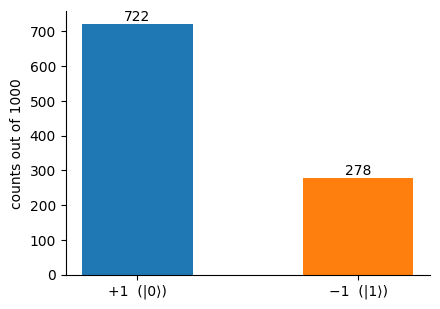

In [77]:
def make_sampler(N):
    dev_N = qml.device("default.qubit", wires=1)
    @qml.set_shots(shots=N) # <-----
    @qml.qnode(dev_N)
    def f(theta):
        qml.RY(theta, wires=0)
        return qml.sample(qml.PauliZ(0))
    return f


z = make_sampler(1000)(theta0)
print("first 20 shots:", z[:20].astype(int))
print(f"N = {len(z)}   <Z> estimate = {z.mean():.3f}  +/-  {z.std(ddof=1) / np.sqrt(len(z)):.3f}   (exact: cos(pi/3) = 0.5)")

fig8, ax8 = plt.subplots(figsize=(4.5, 3.2))
counts = [np.sum(z == 1), np.sum(z == -1)]
bars = ax8.bar(["+1  (|0⟩)", "−1  (|1⟩)"], counts, color=[BLUE, ORANGE], width=0.5)
ax8.bar_label(bars); ax8.set_ylabel("counts out of 1000"); ax8.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## B. Standard error vs N — the chart on slide 29, and the 1/√N law

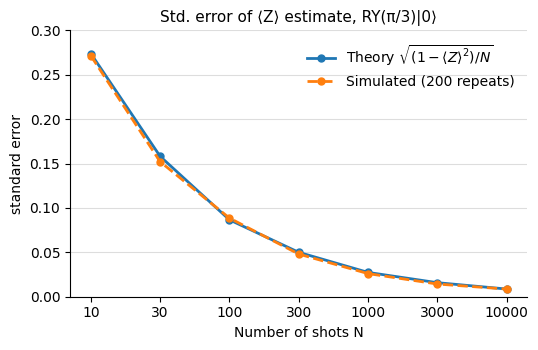

In [78]:
Ns = [10, 30, 100, 300, 1000, 3000, 10000]
repeats = 200
exact = np.cos(theta0)                                   # <Z> = cos(theta) = 0.5

means, spreads, theory_se = [], [], []
for N in Ns:
    sample_N = make_sampler(N)
    ests = np.array([sample_N(theta0).mean() for _ in range(repeats)])
    means.append(ests.mean())
    spreads.append(ests.std(ddof=1))                     # measured fluctuation of the estimate
    theory_se.append(np.sqrt((1 - exact**2) / N))        # SE = sqrt((1 - <Z>^2) / N)

# ---- Figure 1: the chart on slide 29
fig9, ax9 = plt.subplots(figsize=(5.5, 3.6))
x = np.arange(len(Ns))                                   # evenly spaced categories, like the slide
ax9.plot(x, theory_se, "-o", color=BLUE, lw=2, ms=5, label=r"Theory $\sqrt{(1-\langle Z\rangle^2)/N}$")
ax9.plot(x, spreads, "--o", color=ORANGE, lw=2, ms=5, label=f"Simulated ({repeats} repeats)")
ax9.set_xticks(x); ax9.set_xticklabels([str(n) for n in Ns])
ax9.set_xlabel("Number of shots N"); ax9.set_ylabel("standard error")
ax9.set_ylim(0, 0.30); ax9.set_title("Std. error of ⟨Z⟩ estimate, RY(π/3)|0⟩", fontsize=11)
ax9.grid(axis="y", color="#DDDDDD"); ax9.spines[["top", "right"]].set_visible(False)
ax9.legend(loc="upper right", frameon=False)
plt.tight_layout(); plt.show()
